In [41]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import fsolve
from scipy.optimize import curve_fit
%matplotlib inline


In [42]:
#reads in file as 
repsData = pd.read_csv('WI_reps_perdiem_data.csv', thousands=",", encoding='windows-1252') 


In [43]:
print(repsData.columns)

Index(['NAME', 'PARTY', 'DISTRICT', 'DAYS CLAIMED', 'TOTAL'], dtype='str')


In [44]:
#reads in file using pandas, fixes some white space issue in the days claimed column i lost sleep over and spent WAYYYYYY too long on
#also probably a much better way exists but i kinda like that pandas uses the first row as a name for the columns and thats kinda convenient
repsData = pd.read_csv('WI_reps_perdiem_data.csv', thousands=",", encoding='windows-1252') 
repsData.columns = repsData.columns.str.replace("\xa0", " ").str.strip()

#gets rid of the last row 
repsData = repsData.iloc[:-1]
#formats the total column to be just a float number 
repsData["TOTAL"] = repsData["TOTAL"].str.replace("$", "").str.replace(",", "").astype(float)

In [45]:
commiteeData = pd.read_excel('Wisconsin_Assembly_2025_26_Committee_and_Hometown_Data.xlsx')

In [46]:
#Remove bottom row of repsData and turns district to an int
repsData = repsData.iloc[:-1]
repsData['DISTRICT'] = repsData['DISTRICT'].astype(int)

#Sorts based on district
repsData = repsData.sort_values(by='DISTRICT')
commiteeData =commiteeData.sort_values(by='Assembly District')

#Consolidates usable to data to one dataframe
repsData['DISTANCE'] = commiteeData['Approx. Distance to Madison (miles)']
repsData['COMMITTEE COUNT'] = commiteeData['Committee Count']

#Adding Per Diem/Day Column
repsData['PER DIEM / DAY'] = round(repsData['TOTAL'] / repsData['DAYS CLAIMED'], 2)

repsData.head(100)

,NAME,PARTY,DISTRICT,DAYS CLAIMED,TOTAL,DISTANCE,COMMITTEE COUNT,PER DIEM / DAY
16,"Kitchens, Joel",R,1,113.0,15903.0,170,4,140.73
20,"Sortwell, Shae",R,2,113.0,15358.0,60,4,135.91
22,"Steffen, David",R,4,106.0,14845.0,125,5,140.05
18,"Goeben, Joy",R,5,114.0,15475.5,160,2,135.75
87,"Behnke, Elijah",R,6,66.0,7150.0,145,4,108.33
...,...,...,...,...,...,...,...,...
73,"Billings, Jill",D,95,74.0,9107.0,90,3,123.07
41,"Johnson, Tara",D,96,92.0,12280.0,55,6,133.48
88,"Duchow, Cindi",R,97,72.0,7150.0,80,3,99.31
72,"Piwowarczyk, Jim",R,98,86.0,9202.0,90,5,107.00


In [47]:
#Turns all columns into numpy arrays

districtReps = repsData["DISTRICT"].astype(int).to_numpy()
daysClaimed = repsData["DAYS CLAIMED"].astype(int).to_numpy()
perDiem = repsData["TOTAL"].astype(int).to_numpy()
distance = repsData["DISTANCE"].astype(int).to_numpy()
committeeCount = repsData["COMMITTEE COUNT"].astype(int).to_numpy()

perDiemDay = repsData["PER DIEM / DAY"].astype(int).to_numpy()

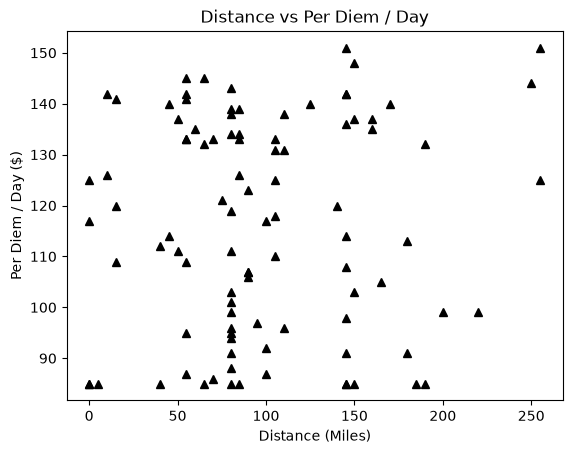

In [49]:
plt.title('Distance vs Per Diem / Day')
plt.xlabel('Distance (Miles)')
plt.ylabel('Per Diem / Day ($)')

plt.plot(distance, perDiemDay, 'k^');

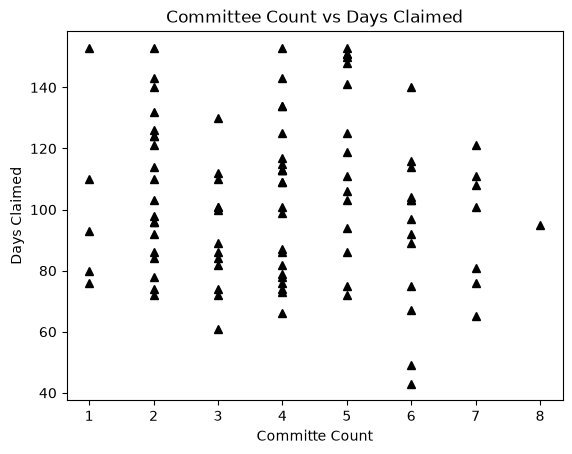

In [50]:
plt.title('Committee Count vs Days Claimed')
plt.xlabel('Committe Count')
plt.ylabel('Days Claimed')

plt.plot(committeeCount, daysClaimed, 'k^');